# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [ ]:

SOURCE_URL = [
    "https://fred.stlouisfed.org/series/ADSGFIA027N",
    "https://fred.stlouisfed.org/series/FEDFUNDS",
    "https://fred.stlouisfed.org/series/A191RL1A225NBEA",
    "https://fred.stlouisfed.org/series/FPCPITOTLZGUSA"
]

DOWNLOAD_DATE = "2026-10-30"

FILE_NAME = [
    "ADSGFIA027N.csv",
    "FEDFUNDS.csv",
    "A191RL1A225NBEA.csv",
    "FPCPITOTLZGUSA.csv"
]


In [6]:
# Load datasets
investment = pd.read_csv("data/ADSGFIA027N.csv")
interest = pd.read_csv("data/FEDFUNDS.csv")
gdp = pd.read_csv("data/A191RL1A225NBEA.csv")
inflation = pd.read_csv("data/FPCPITOTLZGUSA.csv")

# Extract year from dates
for data in [investment, interest, gdp, inflation]:
    data["year"] = pd.to_datetime(data["observation_date"]).dt.year

# Convert monthly interest rates to annual averages
interest = interest.groupby("year", as_index=False)["FEDFUNDS"].mean()

# Calculate annual investment growth
investment["investment_growth"] = investment["ADSGFIA027N"].pct_change() * 100

# Merge datasets by year
df = investment[["year", "investment_growth"]].merge(
    interest, on="year"
).merge(
    gdp[["year", "A191RL1A225NBEA"]], on="year"
).merge(
    inflation[["year", "FPCPITOTLZGUSA"]], on="year"
)

# Rename columns
df = df.rename(columns={
    "FEDFUNDS": "interest_rate",
    "A191RL1A225NBEA": "gdp_growth",
    "FPCPITOTLZGUSA": "inflation"
})

df.head()


,year,investment_growth,interest_rate,gdp_growth,inflation
0,1960,1.387555,3.215833,2.6,1.457976
1,1961,3.573196,1.955000,2.6,1.070724
2,1962,8.067363,2.708333,6.1,1.198773
3,1963,6.464180,3.178333,4.4,1.239669
4,1964,8.177225,3.496667,5.8,1.278912


**Who collected it, for what purpose, what is missing and why?**

The data were downloaded from FRED, maintained by the Federal Reserve Bank of St. Louis. The series come from government statistical agencies and the Federal Reserve and are used to track U.S. economic conditions, including investment, interest rates, GDP growth, and inflation.

The datasets have different date ranges and frequencies, so I will use the overlapping years (1960–2024) and convert monthly interest rates to annual averages. There are no missing values in the final merged dataset. Years outside this range are excluded because not all variables are available, rather than because observations are randomly missing. This is a coverage limitation, not evidence of MCAR.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

The data were downloaded from FRED, maintained by the Federal Reserve Bank of St. Louis. They include gross fixed investment, the federal funds rate, real GDP growth, and inflation in the United States. These series are collected and published by government statistical agencies and the Federal Reserve to track economic conditions.

The datasets have different date ranges and frequencies, so I will merge them by year and use only the overlapping years (1960–2024). I will check for missing values after merging. Years outside the shared date range will be excluded because not all variables are available for those years.

In [7]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "U.S. year"
OUTCOME = "investment_growth"
MAIN_X = "interest_rate"
CONTROLS = ["gdp_growth", "inflation"]


if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 65   Columns: 5   One row is: U.S. year

Missing values per column:
investment_growth    0
interest_rate        0
gdp_growth           0
inflation            0

Skew of investment_growth: -0.49 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Answers:*
1. **Controls:** Real GDP growth and inflation help account for broader economic conditions that may influence both interest rates and investment. However, interest rates can also affect GDP growth, so controlling for GDP growth may remove part of the relationship I want to study. I will compare results with and without this control.

2. **Units:** All observations represent the United States in a given year (1960–2024). Investment growth, GDP growth, inflation, and interest rates are all expressed as percentages or annual rates.

3. **Policy:** This study does not evaluate a specific policy change, so a before-and-after comparison is not required.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

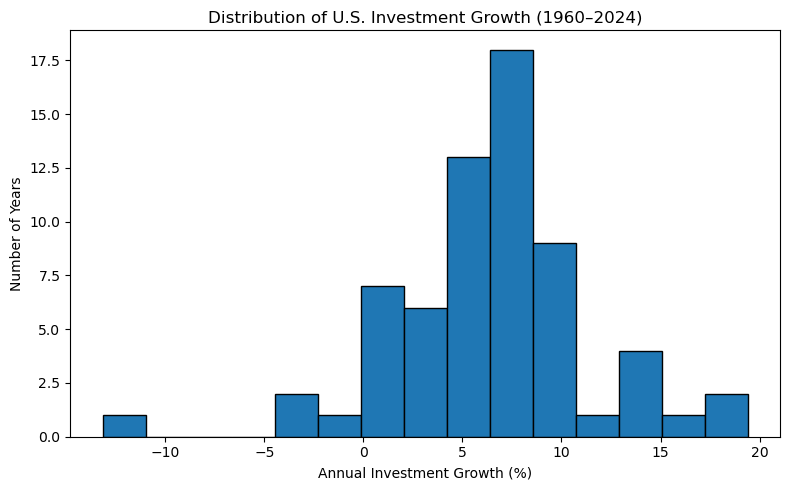

In [8]:
# Figure 1: Distribution of investment growth
plt.figure(figsize=(8, 5))

plt.hist(df["investment_growth"], bins=15, edgecolor="black")

plt.xlabel("Annual Investment Growth (%)")
plt.ylabel("Number of Years")
plt.title("Distribution of U.S. Investment Growth (1960–2024)")

plt.tight_layout()
plt.show()


I am Looking for whether investment growth is concentrated around typical values or has extreme observations. This helps us decide whether OLS is reasonable and whether a transformation might be useful.

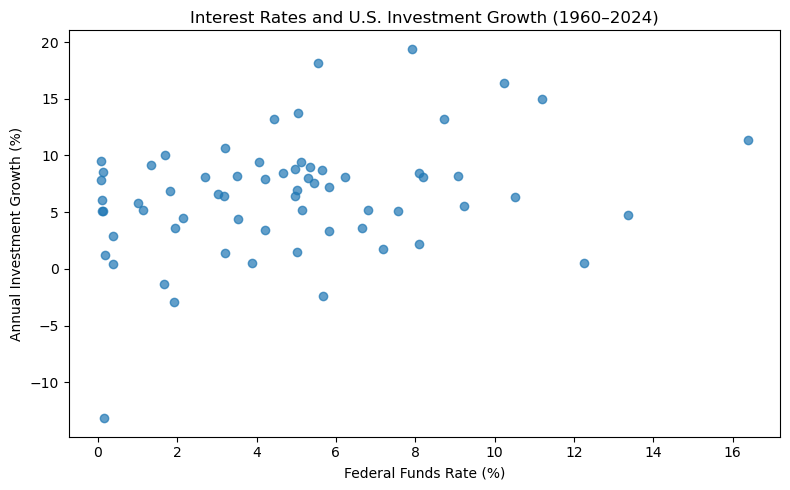

In [9]:
# Figure 2: Interest rates and investment growth
plt.figure(figsize=(8, 5))

plt.scatter(df["interest_rate"], df["investment_growth"], alpha=0.7)

plt.xlabel("Federal Funds Rate (%)")
plt.ylabel("Annual Investment Growth (%)")
plt.title("Interest Rates and U.S. Investment Growth (1960–2024)")

plt.tight_layout()
plt.show()


This scatter plot is important because it related to my question and shows whether years with higher interest rates generally have lower investment growth

**Figure 1:** The distribution of annual investment growth is slightly left-skewed (skewness = −0.49), indicating some years with unusually low growth. Since the skewness is relatively small, I will keep the dependent variable in percentage terms rather than applying a log transformation.

**Figure 2:** The scatterplot shows a [positive/negative/weak or unclear] relationship between interest rates and investment growth. This provides an initial look at the relationship, but does not account for GDP growth or inflation.

Overall, these figures help identify patterns in the data before estimating the regression model.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [15]:
# Relationship between interest rates and investment growth

model_v1 = smf.ols(
    "investment_growth ~ interest_rate",
    data=df
).fit()

# Create regression table
results_v1 = pd.DataFrame({
    "Coefficient": model_v1.params,
    "Std. Error": model_v1.bse,
    "P-value": model_v1.pvalues
})

# Add model statistics
results_v1.loc["Observations"] = [int(model_v1.nobs), np.nan, np.nan]
results_v1.loc["R-squared"] = [model_v1.rsquared, np.nan, np.nan]

display(results_v1.round(3))


,Coefficient,Std. Error,P-value
Intercept,4.370,1.024,0.000
interest_rate,0.429,0.172,0.015
Observations,65.000,NaN,NaN
R-squared,0.090,NaN,NaN


In [16]:
# Adding inflation to model

model_v2 = smf.ols(
    "investment_growth ~ interest_rate + inflation",
    data=df
).fit()

# Create regression table
results_v2 = pd.DataFrame({
    "Coefficient": model_v2.params,
    "Std. Error": model_v2.bse,
    "P-value": model_v2.pvalues
})

# Add model statistics
results_v2.loc["Observations"] = [int(model_v2.nobs), np.nan, np.nan]
results_v2.loc["R-squared"] = [model_v2.rsquared, np.nan, np.nan]

display(results_v2.round(3))


,Coefficient,Std. Error,P-value
Intercept,3.853,1.073,0.001
interest_rate,0.165,0.246,0.505
inflation,0.474,0.321,0.145
Observations,65.000,NaN,NaN
R-squared,0.121,NaN,NaN


In [17]:
# Compare Version 1 and Version 2
comparison = pd.DataFrame({
    "Version 1": [
        model_v1.params["interest_rate"],
        model_v1.pvalues["interest_rate"],
        model_v1.rsquared
    ],
    "Version 2": [
        model_v2.params["interest_rate"],
        model_v2.pvalues["interest_rate"],
        model_v2.rsquared
    ]
}, index=[
    "Interest Rate Coefficient",
    "Interest Rate P-value",
    "R-squared"
])

display(comparison.round(3))


,Version 1,Version 2
Interest Rate Coefficient,0.429,0.165
Interest Rate P-value,0.015,0.505
R-squared,0.090,0.121


### Version 2: Adding Inflation

In Version 2, I added inflation as a control because it may influence both interest rates and nominal investment growth.

After adding inflation, the interest-rate coefficient decreased from 0.429 to 0.165, and the p-value increased from 0.015 to 0.505. This means the relationship is no longer statistically significant at the 5% level. R-squared increased slightly from 0.090 to 0.121.

These results suggest that inflation may explain part of the relationship observed in Version 1. However, the model still does not account for overall economic growth.

In [18]:
#Adding real GDP growth to the model
model_v3 = smf.ols(
    "investment_growth ~ interest_rate + inflation + gdp_growth",
    data=df
).fit()

# Create regression table
results_v3 = pd.DataFrame({
    "Coefficient": model_v3.params,
    "Std. Error": model_v3.bse,
    "P-value": model_v3.pvalues
})

# Add model statistics
results_v3.loc["Observations"] = [int(model_v3.nobs), np.nan, np.nan]
results_v3.loc["R-squared"] = [model_v3.rsquared, np.nan, np.nan]

display(results_v3.round(3))


,Coefficient,Std. Error,P-value
Intercept,-2.749,0.760,0.001
interest_rate,-0.224,0.132,0.095
inflation,1.077,0.174,0.000
gdp_growth,2.048,0.159,0.000
Observations,65.000,NaN,NaN
R-squared,0.764,NaN,NaN


In [19]:
# Compare all three model versions
comparison = pd.DataFrame({
    "Version 1": [
        model_v1.params["interest_rate"],
        model_v1.pvalues["interest_rate"],
        model_v1.rsquared
    ],
    "Version 2": [
        model_v2.params["interest_rate"],
        model_v2.pvalues["interest_rate"],
        model_v2.rsquared
    ],
    "Version 3": [
        model_v3.params["interest_rate"],
        model_v3.pvalues["interest_rate"],
        model_v3.rsquared
    ]
}, index=[
    "Interest Rate Coefficient",
    "Interest Rate P-value",
    "R-squared"
])

display(comparison.round(3))


,Version 1,Version 2,Version 3
Interest Rate Coefficient,0.429,0.165,-0.224
Interest Rate P-value,0.015,0.505,0.095
R-squared,0.090,0.121,0.764


### Version 3: Adding Real GDP Growth

In Version 3, I added real GDP growth to account for overall economic activity.

The interest-rate coefficient changed from +0.165 in V2 to −0.224 in V3, while R-squared increased from 0.121 to 0.764. This suggests that GDP growth explains a substantial amount of the variation in investment growth.

The interest-rate coefficient is negative but is not statistically significant at the 5% level (p = 0.095). GDP growth has a positive coefficient of 2.048 (p < 0.001), indicating that a one-percentage-point increase in GDP growth is associated with a 2.048-percentage-point increase in investment growth, holding the other variables constant.

However, GDP growth may be a problematic control because investment contributes to GDP and interest rates may affect GDP growth. Therefore, the higher R-squared does not necessarily make V3 a better model for estimating the relationship between interest rates and investment.

### Table 1. OLS Models of Annual U.S. Gross Fixed Investment Growth (1960–2024)

*Dependent variable: Annual nominal gross fixed investment growth (%).*

Coefficients are reported with standard errors in parentheses. All models use annual U.S. observations. V1 includes only the federal funds rate; V2 adds inflation; V3 additionally includes real GDP growth.

In [20]:
# Final regression comparison table

models = {
    "V1: Baseline": model_v1,
    "V2: + Inflation": model_v2,
    "V3: + GDP Growth": model_v3
}

variables = [
    "Intercept",
    "interest_rate",
    "inflation",
    "gdp_growth"
]

table = pd.DataFrame(index=variables)

for name, model in models.items():
    table[name] = [
        f"{model.params.get('Intercept', np.nan):.3f} "
        f"({model.bse.get('Intercept', np.nan):.3f})",

        f"{model.params['interest_rate']:.3f} "
        f"({model.bse['interest_rate']:.3f})",

        (f"{model.params['inflation']:.3f} "
         f"({model.bse['inflation']:.3f})")
        if "inflation" in model.params else "—",

        (f"{model.params['gdp_growth']:.3f} "
         f"({model.bse['gdp_growth']:.3f})")
        if "gdp_growth" in model.params else "—"
    ]

# Add model statistics
table.loc["Observations"] = [
    str(int(m.nobs)) for m in models.values()
]

table.loc["R-squared"] = [
    f"{m.rsquared:.3f}" for m in models.values()
]

# Improve row labels
table = table.rename(index={
    "interest_rate": "Federal Funds Rate",
    "inflation": "Inflation",
    "gdp_growth": "Real GDP Growth"
})

display(table)


,V1: Baseline,V2: + Inflation,V3: + GDP Growth
Intercept,4.370 (1.024),3.853 (1.073),-2.749 (0.760)
Federal Funds Rate,0.429 (0.172),0.165 (0.246),-0.224 (0.132)
Inflation,—,0.474 (0.321),1.077 (0.174)
Real GDP Growth,—,—,2.048 (0.159)
Observations,65,65,65
R-squared,0.090,0.121,0.764


### Model Comparison

The three models show how adding controls changes the estimated relationship between interest rates and investment growth.

In V1, interest rates have a positive coefficient of 0.429 (p = 0.015), but the model explains only 9.0% of the variation in investment growth.

After adding inflation in V2, the interest-rate coefficient decreases to 0.165 (p = 0.505), and R-squared increases slightly to 0.121.

In V3, adding real GDP growth changes the interest-rate coefficient to −0.224 (p = 0.095), while R-squared increases to 0.764.

Although V3 explains more variation, GDP growth may be a problematic control because investment is part of GDP and interest rates may influence economic growth. Therefore, the three models demonstrate how sensitive the estimated relationship is to the choice of controls rather than proving that one model is necessarily better.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

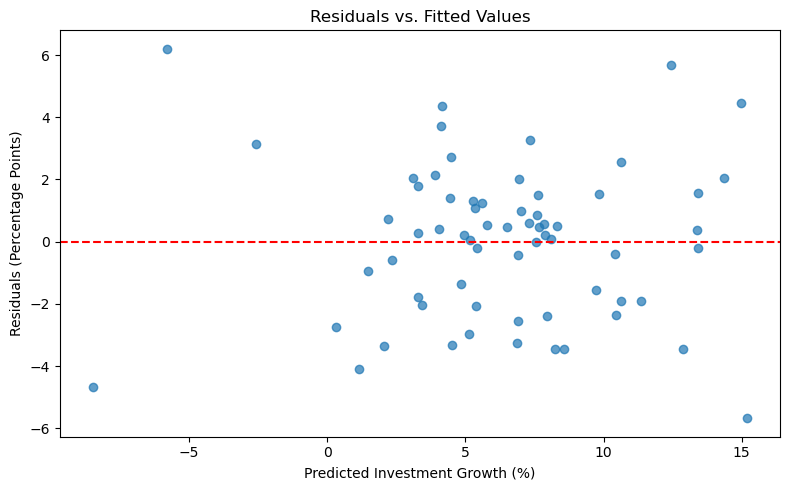

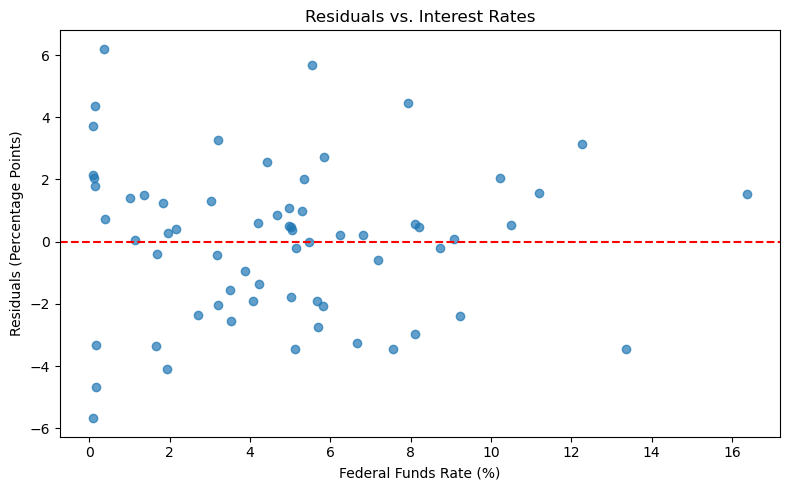

In [ ]:
# Section 4: Residual diagnostics for Version 3

# Get predicted values and residuals
fitted = model_v3.fittedvalues
residuals = model_v3.resid

# Residuals vs. fitted values
plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Investment Growth (%)")
plt.ylabel("Residuals (Percentage Points)")
plt.title("Residuals vs. Fitted Values")

plt.tight_layout()
plt.show()

# Residuals vs. interest rates
plt.figure(figsize=(8, 5))
plt.scatter(df["interest_rate"], residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Federal Funds Rate (%)")
plt.ylabel("Residuals (Percentage Points)")
plt.title("Residuals vs. Interest Rates")

plt.tight_layout()
plt.show()


### Residual Diagnostics

I examined residual plots against fitted values and interest rates. Both plots show residuals scattered around zero without a clear curved pattern, suggesting the linear specification is reasonable.

However, there are some large residuals and uneven variation across observations. I will use a formal test to check for heteroskedasticity and examine whether any observations have a strong influence on the model.

In [22]:

# Breusch-Pagan test for heteroskedasticity
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model_v3.resid,
    model_v3.model.exog
)

print("Breusch-Pagan Test")
print("LM Statistic:", round(bp_test[0], 3))
print("P-value:", round(bp_test[1], 4))


Breusch-Pagan Test
LM Statistic: 6.899
P-value: 0.0752


### Heteroskedasticity Test

I used the Breusch–Pagan test to check whether the residuals have constant variance. The test produced an LM statistic of 6.899 and a p-value of 0.0752.

Since the p-value is greater than 0.05, I fail to reject the null hypothesis of constant variance at the 5% significance level. However, the result is significant at the 10% level, suggesting some possible heteroskedasticity.

I will compare the original standard errors with robust standard errors to check whether this affects my conclusions.

In [23]:
# Calculate HC3 robust standard errors
model_robust = model_v3.get_robustcov_results(cov_type="HC3")

# Compare original and robust standard errors
se_comparison = pd.DataFrame({
    "Original SE": model_v3.bse,
    "Robust SE (HC3)": model_robust.bse,
    "Original P-value": model_v3.pvalues,
    "Robust P-value": model_robust.pvalues
}, index=model_v3.params.index)

display(se_comparison.round(4))


,Original SE,Robust SE (HC3),Original P-value,Robust P-value
Intercept,0.7601,1.2650,0.0006,0.0336
interest_rate,0.1324,0.1739,0.0955,0.2022
inflation,0.1742,0.2383,0.0000,0.0000
gdp_growth,0.1591,0.2790,0.0000,0.0000


### Robust Standard Errors

I compared the original OLS standard errors with HC3 robust standard errors to account for possible heteroskedasticity.

The robust standard errors increased for all variables. For interest rates, the standard error increased from 0.1324 to 0.1739, and the p-value increased from 0.0955 to 0.2022. This suggests greater uncertainty around the estimated interest-rate relationship.

Inflation and GDP growth remained statistically significant at the 5% level, even with robust standard errors. Overall, the results reinforce that there is insufficient evidence of a statistically significant relationship between interest rates and investment growth in the full model.

In [24]:
# Check multicollinearity using VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Get explanatory variables from Version 3
X = model_v3.model.exog
names = model_v3.model.exog_names

# Calculate VIF for each variable
vif = pd.DataFrame({
    "Variable": names,
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

# Exclude intercept from interpretation
vif = vif[vif["Variable"] != "Intercept"]

display(vif.round(2))


,Variable,VIF
1,interest_rate,2.22
2,inflation,2.26
3,gdp_growth,1.08


### Multicollinearity Check

I calculated variance inflation factors (VIF) to check for multicollinearity among the explanatory variables.

The VIF values were 2.22 for interest rates, 2.26 for inflation, and 1.08 for GDP growth. Since all values are below 5, there is no evidence of serious multicollinearity. Interest rates and inflation have some overlap, but not enough to suggest removing either variable.

In [25]:
# Check influential observations using Cook's distance
influence = model_v3.get_influence()
cooks_d = influence.cooks_distance[0]

# Add Cook's distance to the dataset
df_influence = df.copy()
df_influence["cooks_distance"] = cooks_d

# Screening threshold
threshold = 4 / len(df)

print("Cook's distance threshold:", round(threshold, 4))

# Show observations above the threshold
influential = df_influence[
    df_influence["cooks_distance"] > threshold
]

display(
    influential[["year", "cooks_distance"]]
    .sort_values("cooks_distance", ascending=False)
    .round(4)
)


Cook's distance threshold: 0.0615


,year,cooks_distance
61,2021,0.3220
60,2020,0.2780
49,2009,0.2473
20,1980,0.1834
22,1982,0.1352
17,1977,0.0840
18,1978,0.0754


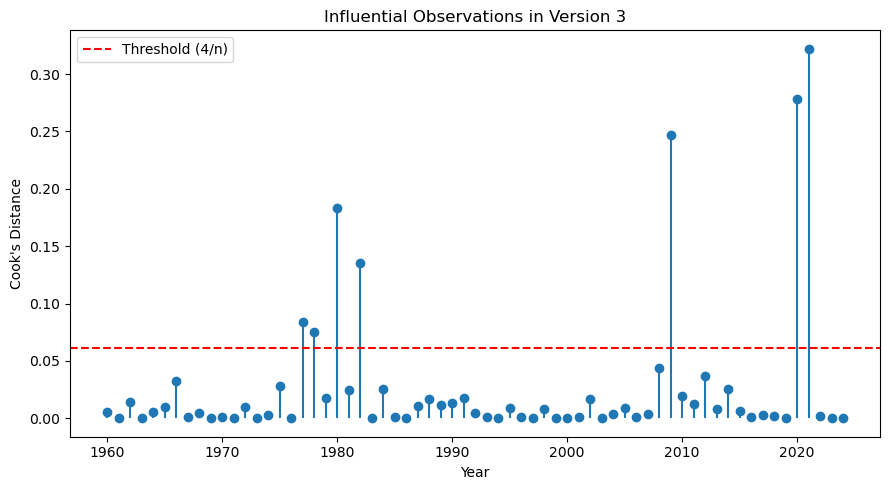

In [26]:
# Plot Cook's distance by year
plt.figure(figsize=(9, 5))

plt.stem(
    df_influence["year"],
    df_influence["cooks_distance"],
    basefmt=" "
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold (4/n)"
)

plt.xlabel("Year")
plt.ylabel("Cook's Distance")
plt.title("Influential Observations in Version 3")
plt.legend()

plt.tight_layout()
plt.show()


### Influential Observations

I used Cook's distance to identify observations that may have a strong influence on my regression results. Seven years exceeded the screening threshold of 0.0615: 1977, 1978, 1980, 1982, 2009, 2020, and 2021.

The most influential observations were 2021 (0.3220), 2020 (0.2780), and 2009 (0.2473). These years coincide with major economic disruptions, which may explain why they differ from other observations.

I will keep these years in the main model because they represent real economic conditions, but I will check whether excluding them changes my results.

### Diagnostics Summary

Overall, the diagnostic tests suggest that the model has some limitations but remains useful for examining the relationship between interest rates and investment growth.

The residual plots did not show a clear nonlinear pattern. The Breusch–Pagan test found limited evidence of heteroskedasticity, while the VIF results suggested that multicollinearity is not a major concern.

Robust standard errors increased the uncertainty around the interest-rate coefficient, and Cook's distance identified seven potentially influential years. These results suggest that the estimated relationship should be interpreted cautiously rather than as evidence of causation.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [4]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.